# Thunderous Fury (Templar)

Thunderous Fury is an upgraded Warcry. Every hostile within 10 tiles that fails the Warcry check
is stunned for 3 s, loses 15 from every attribute for 60 s, and takes a spell-type damage blast.
It costs 250 endurance and has a 30 s cooldown.

| | |
|---|---|
| Class | Templar |
| Target | Every character in the 21×21 square around the caster (±10 tiles, inclusive) that passes `warcry()` |
| Cost | 250 endurance, spent first |
| Cooldown | 30 s, started even if nobody is hit |
| Landing roll | **deterministic**: `power >= effective_resist(Resist)`; no d20, no immunity |
| Effect | War-Stun (`SK_WARCRY2`, 3 s, stunned) + Warcry (`SK_WARCRY`, −15 to all attributes, 60 s) + `do_hurt(dam, 1)` |
| Skipped | group members (`data[1..10]`), immortals, alignment-10000 characters other than the caster's current target, anyone `may_aoe_attack` rejects |
| Source | `server/src/driver/skill/templar.rs::skill_thunderous_fury`, `warcry` |

---

# Formula

With $p$ the raw modified skill:

$$
b = \max\!\left(1,\ \left\lfloor 3p/4 \right\rfloor\right)
\qquad
\text{dam} = b + \text{rand}(b)
\qquad
\text{HP removed} = \tfrac{3}{4}\max(0,\ \text{dam} - \text{armor})
$$

`do_hurt` type 1 is spell damage: armor is still subtracted, and each remaining point removes
0.75 HP (melee removes 0.25). The gate compares the raw skill with the target's Resist:

$$
\text{affected} \iff p \ge R_\text{eff}
\qquad
R_\text{eff} = \left\lfloor \frac{100 R}{100 + \text{pen}} \right\rfloor
$$

The Warcry debuff removes 15 from each of Resist's three attributes, so it lowers the target's
Resist by 9 for 60 s. The next cast, 30 s later, gets through 9 more points of Resist.

| Quantity | Breakpoint |
|---|---|
| Blast at the raise caps | $b$ = 78 at 105 (dam 78–155), 90 at 120 (dam 90–179) |
| Ceiling | none: the blast grows linearly with skill |
| Highest Resist affected | $p$ (or $p + 9$ while a previous Warcry debuff is up) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
COOLDOWN_S = 30
END_COST = 250
STUN_S = 3
WEAKEN_S = 60
WARCRY_RESIST_DROP = 15 * 3 // 5

# Model

In [2]:
def blast_base(p):
    return np.maximum(1, mm.idiv(np.asarray(p) * 3, 4))


def blast_hp(p, armor=0):
    """Expected HP removed from one affected target."""
    b = blast_base(p)
    return mm.expected_hurt_uniform(b, b, armor, kind=1)


def affected(p, resist, pen_pct=0, weakened=False):
    r = mm.effective_resist(np.asarray(resist) - (WARCRY_RESIST_DROP if weakened else 0), pen_pct)
    return np.asarray(p) >= r

# Validation

- `thunderous_fury_spends_endurance_and_starts_cooldown`: 300,000 → 50,000, cooldown `TICKS*30`.
- `warcry_stuns_and_weakens_the_target`: power 40 → War-Stun power 40 for `TICKS*3`, Warcry power
  20 with −15 on every attribute.
- `warcry_spares_resistant_immortal_and_friendly_targets`: Resist 100 blocks power 40.
- `endurance_skills_do_nothing_without_enough_endurance`: 74,000 endurance is refused.

In [3]:
assert 300_000 - END_COST * 1000 == 50_000 and 74_000 < END_COST * 1000
assert mm.TICKS * COOLDOWN_S == 1080 and mm.TICKS * STUN_S == 108
assert not affected(40, 100) and affected(40, 40) and not affected(40, 41)
assert WARCRY_RESIST_DROP == 9 and affected(40, 49, weakened=True)
assert blast_base(105) == 78 and blast_base(120) == 90 and blast_base(1) == 1
# b = 78: dam 78..155, mean 116.5, x 0.75
assert blast_hp(105) == 116.5 * 0.75
print("Thunderous Fury model OK")

Thunderous Fury model OK


# Plots

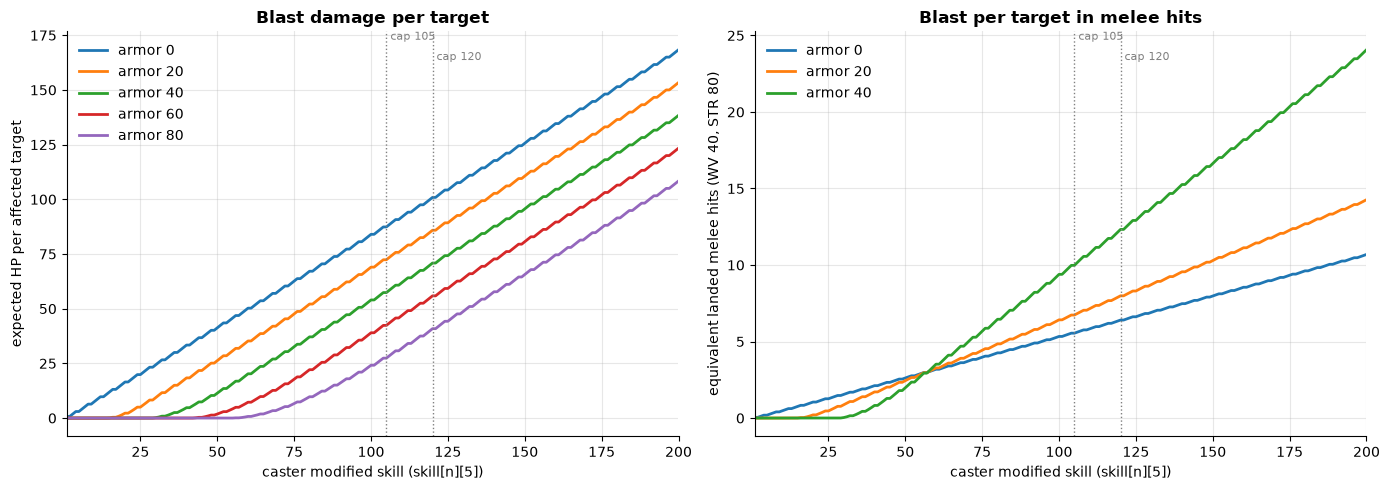

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for armor in mm.ARMOR_SWEEP:
    ax.plot(P, blast_hp(P, armor), label=f"armor {armor}")
mm.skill_axis(ax, "expected HP per affected target", "Blast damage per target")
mm.mark_caps(ax)
ax.legend()

# The same blast measured in landed melee hits of a WV-40 STR-80 Templar against the same armor.
ax = axes[1]
for armor in (0, 20, 40):
    ax.plot(P, blast_hp(P, armor) / mm.melee_hit_hp(40, 80, armor), label=f"armor {armor}")
mm.skill_axis(ax, "equivalent landed melee hits (WV 40, STR 80)", "Blast per target in melee hits")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

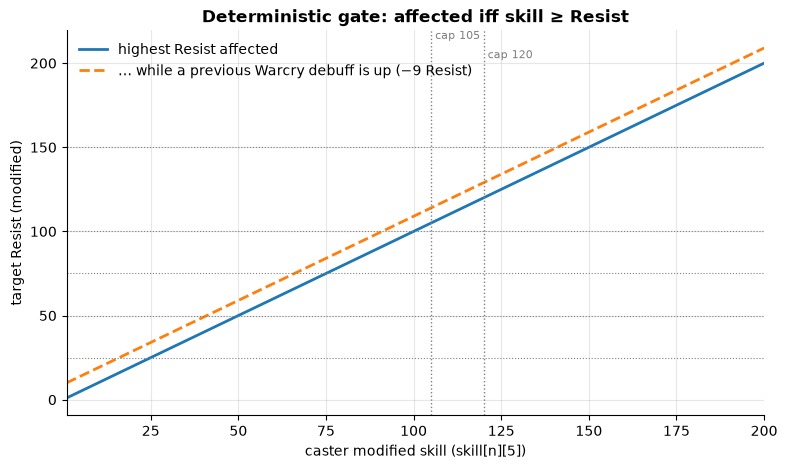

In [5]:
fig, ax = plt.subplots()
ax.plot(P, P, label="highest Resist affected")
ax.plot(P, P + WARCRY_RESIST_DROP, ls="--", label="… while a previous Warcry debuff is up (−9 Resist)")
for r in mm.RESIST_SWEEP:
    ax.axhline(r, color="grey", lw=0.8, ls=":")
mm.skill_axis(ax, "target Resist (modified)", "Deterministic gate: affected iff skill ≥ Resist")
mm.mark_caps(ax)
ax.legend(loc="upper left")

# Observations

- **A large, armor-light AoE nuke.** At skill 105 every affected target takes 87 HP on average
  (armor 0) and 72 HP at armor 20. That is 5.5 to 10 landed hits of a WV-40 STR-80 Templar, and it
  lands on every hostile in a 21×21 square at once. Each point of armor costs only 0.75 HP, so
  armor 40 still lets 57 HP through.
- **The gate is all-or-nothing.** There is no d20 and no immunity reduction: a target with Resist
  ≤ $p$ is always stunned, weakened and blasted, and one with Resist > $p$ never is. A target sitting
  just above the caster's skill is completely immune, until another Warcry source lowers its
  Resist by 9.
- **The stun is short; the debuff and the damage are the payload.** War-Stun lasts 3 s of every
  30 s cycle (10%). The −15 attributes last 60 s, so with recasts on cooldown the debuff is
  permanent on anything that stays in range. It also lowers the target's Resist by 9, which makes
  the next cast easier to land.
- **Endurance efficiency.** 250 endurance buys 87 HP per target at skill 105 (0.35 HP per
  endurance per target). Against five targets that is 437 HP for one action.
- **Seeing Red counters only the stun.** A Templar under Seeing Red refuses War-Stun but still
  receives the Warcry debuff and the full damage.
- **Code comments.** "Spell-type damage (like Blast) so armor does not swallow it" is
  misleading: type 1 still subtracts armor. It only converts each remaining point at 0.75 HP
  instead of 0.25.
- **Balance suggestions.** Scale the blast from $p/2$ instead of $3p/4$, or fall off with
  distance from the caster. Replacing the deterministic gate with the usual opposed d20
  (`p + rand(20) > R + rand(20)`) would also smooth out the all-or-nothing cliff at Resist ≈ skill.